## Imports

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import holidays as holidays_lib
import requests
from typing import Literal
import seaborn as sns

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

## Helper Functions

### Data collection

In [ ]:
def _clean_ktm_data(df:pd.DataFrame, year:str) -> pd.DataFrame:
    df = df.copy()

    ## 1. Remove ridership that is negative
    df = df[df['ridership'] > 0]

    ## 2. Remove station that is 'Unknown;
    df = df[df['origin'] != 'Unknown'] 
    df = df[df['destination'] != 'Unknown']

    ## 3. Remove duplicates
    df = df.drop_duplicates()

    ## 4. Remove rows with missing values
    df = df.dropna()
    
    ## 5. Make sure the year is on the specified year
    
    df = df[df['date'].dt.year == int(year)]
    
    ## 6. Retain only operational hour (6AM to 11PM)
    cond = df['datetime'].dt.hour.between(0,5)
    df = df[cond]
    return df

def get_clean_ktm_data(year:int)->pd.DataFrame:
    """
    Get Official KTMB data from 'https://storage.data.gov.my/transportation/ktmb/{year}.parquet'
    """
    
    URL_DATA = f'https://storage.data.gov.my/transportation/ktmb/komuter_{year}.parquet'
    
    # Read data
    df = pd.read_parquet(URL_DATA, engine='fastparquet')
    
    # Cast datetime format
    if 'date' in df.columns:
        df['date'] = pd.to_datetime(df['date'])
    
    df['datetime'] = df['date'] + pd.to_timedelta(df['time'] + ':00')
        
    return _clean_ktm_data(df, year)

In [ ]:
def get_weather_data(year:int, weather_features: list) -> pd.DataFrame:
    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={
            "latitude": 3.139, "longitude": 101.6869,          # Kuala Lumpur
            "start_date": f"{year}-01-01", "end_date": f"{year}-12-31",
            "hourly": ",".join(weather_features),
            "timezone": "Asia/Kuala_Lumpur",
        },
        timeout=60,
    )
    response.raise_for_status()
    df =  pd.DataFrame(response.json()["hourly"]).rename(columns={'time':'datetime'})
    
    df['datetime'] = pd.to_datetime(df['datetime'])

    cond = df['datetime'].dt.hour.between(0,5)
    
    return df[cond]


def get_temporal_data(year:int)->pd.DataFrame:
    YEAR_HOURS = pd.date_range(f"{year}-01-01", f"{year}-12-31 23:00", freq="h")
    
    ### First-level (base)
    my_holidays = holidays_lib.Malaysia(years=sorted(set(YEAR_HOURS.year)), subdiv="KUL")
    day_of_week = YEAR_HOURS.dayofweek.to_numpy()
    hour = YEAR_HOURS.hour.to_numpy()

    ### Second-levek (derrived from first-level) 
    hour_sin = np.sin(2 * np.pi * hour / 24)
    hour_cos = np.cos(2 * np.pi * hour / 24)
    dow_sin = np.sin(2 * np.pi * day_of_week / 7)
    dow_cos = np.cos(2 * np.pi * day_of_week / 7)
    is_weekend = (day_of_week >= 5).astype(float)
    is_holiday = np.array([d in my_holidays for d in YEAR_HOURS.date], dtype=float)
    
    column_name = ['hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'is_weekend', 'is_holiday']
    
    np_stack = np.stack([
        hour_sin, hour_cos, dow_sin, dow_cos, is_weekend, is_holiday,
    ], axis=1)
    
    joined_df = pd.DataFrame(np_stack, columns=column_name, index=YEAR_HOURS).reset_index().rename(columns={'index':'datetime'})
    
    cond = joined_df['datetime'].dt.hour.between(0,5)
    
    return joined_df[cond] 

In [5]:
def join_all_df(ktm_df:pd.DataFrame, weather_df:pd.DataFrame, temporal_df:pd.DataFrame)->pd.DataFrame:
    
    selected_cols = ['datetime', 'origin', 'destination', 'ridership']
        
    ktm_df['od'] = ktm_df['origin'] + '_' + ktm_df['destination']

    ktm_df = ktm_df[selected_cols]
    
    joined_df = ktm_df.merge(
        weather_df, on='datetime', how='left'
    ).merge(
        temporal_df, on='datetime', how='left'
    )
    
    return joined_df

In [101]:
def convert_df_to_numpy(df:pd.DataFrame, cols_to_drop:list[str])->np.ndarray:
    
    return df.drop(columns=cols_to_drop).to_numpy()

In [ ]:
def make_windows_tabular(
    ktm_np:np.ndarray,
    lookback:int,
    horizon:int
):
    
    n_hours, n_stations = ktm_np.shape

    lag_cols = [f"lag_{h}" for h in range(lookback, 0, -1)]
    
    frames = []
    for i in range(n_hours - lookback):
        x = ktm_np[i : i + lookback].T
        y = ktm_np[i+lookback : i + lookback + horizon].T
        
        df = pd.DataFrame(x, columns=lag_cols)
        
        df['station'] = STATIONS_LIST
        df['datetime'] = DT_INDEX[i+lookback]
        df['window'] = i
        df['target'] = y
        
        frames.append(df)

    return pd.concat(frames, ignore_index=True)


### Graph Structure

In [7]:
## Core KTM Ridership 

def build_station_series(
    ktm_df:pd.DataFrame,
    datetime_index:pd.DatetimeIndex,
    stations:list
) -> np.ndarray:
    
    """
    Convert KTM tabular data to numpy format.
    """
    
    agg_df = ktm_df.groupby([ktm_df['datetime'].dt.floor('h'), 'origin'])['ridership'].sum()
    
    # Pivot from long format to wide format
    # To fill 0 for stations without ridership at certain datetime
    # whereby other stations have data
    pivot_df = agg_df.unstack(fill_value=0) 
    
    # Reindex based on intialised value upstream (to ensure parity)
    # To fill 0 for stations that never appear as origin
    # or datetime (index) that has no data at all
    pivot_df = pivot_df.reindex(index=datetime_index, columns=stations, fill_value=0)
    
    # Convert to numpy
    numpy_df = pivot_df.to_numpy(dtype=np.float32)
    
    return numpy_df



In [8]:
def append_feature_tabular(
    ktm_windowed_df:pd.DataFrame,
    feature_dfs:list[pd.DataFrame]
)-> pd.DataFrame:
    
    joined_df = ktm_windowed_df.copy()
    
    for df in feature_dfs:
        joined_df = joined_df.merge(
            df.drop_duplicates(subset='datetime'),
            on='datetime',
            how='left'
        )

    return joined_df

In [9]:
## Append additional features

def append_feature_graph(
    ridership_np : np.ndarray,
    feature_dfs: list[pd.DataFrame],
    datetime_index : pd.DatetimeIndex
)->np.ndarray:
    
    n_hours, n_stations = ridership_np.shape
    
    # Ridership [H, N] -> [H, N, 1]
    blocks = [ridership_np[:,:,np.newaxis]]
    
    # Pre-process the DF
    for df in feature_dfs:
        # 1. Line up rows with the ridership hours (same order, exactly H rows)
        df = df.drop_duplicates(subset='datetime').set_index('datetime')
        df = df.reindex(datetime_index)
        df = df.interpolate().ffill().bfill()            # fill any missing hours

        # 2. Tabular -> numpy: [H, k]
        values = df.to_numpy(dtype=np.float32)

        # 3. Copy the same values to every station: [H, k] -> [H, 1, k] -> [H, N, k]
        values = values[:, np.newaxis, :]
        values = np.repeat(values, n_stations, axis=1)

        blocks.append(values)
    
    # 4. Glue along the feature axis
    return np.concatenate(blocks, axis=-1)

In [10]:
## Adjacency Matrix

def build_od_flow(ktm_df:pd.DataFrame,
                  STATIONS_LIST:list[str]
) -> np.ndarray :
    """
    Aggregate the daily tabular KTM data
    into a total annual ridership per origin-destination.
    
    Output format is {'origin: destination'}, ridership
    
    """
    
    # Obtain annual ridership for each origin-destination pair
    od_agg_df = ktm_df.groupby(['origin', 'destination'])['ridership'].sum()
    
    # Establish station index dict
    station_idx = {s:i for i, s in enumerate(STATIONS_LIST)}
    
    # Initialise empty numpy array to store the OD ridership
    od_flow = np.zeros((len(STATIONS_LIST), len(STATIONS_LIST)), dtype=np.float32)
    
    for (o,d), ridership in od_agg_df.items():
        od_flow[station_idx[o], station_idx[d]] = ridership
    
    return od_flow + od_flow.T

def build_adjacency_matrix(od_flow:np.ndarray, threshold:int)->np.ndarray:
    """
    Build Origin-Destination (OD) adjacency matrix.

    If the annual sum of an OD exceeds the defined threshold,
    we consider that the stations are connected.
    
    We represent this connection through a matrix of Origin station (row-level)
    to Destination station (column-level).
    
    If the connection is present, we fill an integer 1, else 0.
    """
    
    adj = (od_flow >= threshold).astype(np.float32)
    
    np.fill_diagonal(adj, 0) 

    return adj

def normalize_adjacency_matrix(
    adj_matrix: np.ndarray
)-> np.ndarray:
    """
    A_hat = D^-1/2 (A + I) D^-1/2  (Kipf & Welling GCN normalisation).
    """
    
    a_tilde = adj_matrix + np.eye(len(adj_matrix)) # 1. Add self-loops
    degree = a_tilde.sum(axis=1) # 2. Degree of each station
    d_inv_sqrt = np.diag(1.0 / np.sqrt(degree)) #3. D^-1/2 as a diagonal matrix
    
    return (d_inv_sqrt @ a_tilde @ d_inv_sqrt).astype(np.float32) # 4. Sandwich

### Modelling

In [11]:
class DenseGCNLayer(nn.Module):
    """One GCN layer, dense form: A_hat @ X @ W + b (bias added after aggregation).

    Expects a pre-normalised adjacency (see data.normalize_adjacency). A_hat
    broadcasts over any leading dimensions, so x may be [N, F], [B, N, F] or
    [B, T, N, F] — the same layer serves every timestep of every sample at once.
    """

    def __init__(self, in_features: int, out_features: int) -> None:
        super().__init__()
        self.linear = nn.Linear(in_features, out_features, bias=False)
        self.bias = nn.Parameter(torch.zeros(out_features))

    def forward(self, x: torch.Tensor, a_hat: torch.Tensor) -> torch.Tensor:
        return a_hat @ self.linear(x) + self.bias


class STGNN(nn.Module):
    def __init__(self,
                 in_features: int,
                 hidden_dim: int,
                 num_gcn_layers:int,
                 horizon:int,
                 dropout:float
                )->None:
        super().__init__()
        
        dims = [in_features] + [hidden_dim] * num_gcn_layers
        
        self.gcn_layers = nn.ModuleList(
            DenseGCNLayer(dims[i], dims[i+1]) for i in range(num_gcn_layers)
        ) # Spatial Layer
        
        self.gru = nn.GRU(hidden_dim, hidden_dim, batch_first=True) # Temporal Layer
        self.head = nn.Linear(hidden_dim, horizon) # Final output layer
        self.dropout = dropout
    
    def forward(self, x:torch.Tensor, a_hat: torch.Tensor)-> torch.Tensor:
        h = x
        
        for layer in self.gcn_layers:
            h = F.relu(layer(h, a_hat))
            h = F.dropout(h, self.dropout, self.training)
        
        b, t, n, d = h.shape # b (batch size, timestep, nodes-stations) # temporal: GRU per station
        seq = h.permute(0,2,1,3).reshape(b*n, t, d)
        _, last_hidden = self.gru(seq)
        
        return self.head(last_hidden.squeeze(0)).view(b, n, -1)

In [12]:
def make_windows(series:np.ndarray,
                 lookback:int
) -> tuple[np.ndarray, np.ndarray]:
    xs, ys = [], []
    for i in range(len(series) - lookback):
        xs.append(series[i:i+lookback]) # [T, N, F]  all features
        ys.append(series[i+lookback, :, 0:1]) # [N, 1] ridership only (0:1 keeps the axis)
    
    x = np.stack(xs)
    y = np.stack(ys)
    
    # Add a feature axis which the model expects [S, T, N, F]
    # S: Samples (sliding windows) = n_hours - lookback, 8761 here
    # T: Timesteps per window = lookback (23 hourly snapshots)
    # N: Nodes (number of stations)
    # F: Number of features, 1 for ridership
    
    # x: [S, T, N, F]   y: [S, N, 1]
    return x , y

In [ ]:
## Train-test split
def split_train_valid_test(x, y, train_prop=0.70, test_prop=0.30):
    n_samples = len(x)
    n_train = int(n_samples * train_prop)
    n_test= int(n_samples * test_prop)

    x_train, y_train = x[:n_train], y[:n_train]
    x_test, y_test = x[n_train+n_test:], y[n_train+n_test:]

    return (x_train, y_train), (x_test, y_test)

In [14]:
## Scale data

def scale_data(data, x_mean, x_std, y_mean, y_std):
    x, y = data
    
    x_scaled = (x - x_mean) / x_std
    y_scaled = (y - y_mean) / y_std
    
    return (x_scaled, y_scaled)

In [15]:
def fit(model: nn.Module, 
        optimiser: torch.optim.Optimizer, 
        train_data: tuple[np.ndarray, np.ndarray], 
        a_hat: np.ndarray,
        n_epoch:int,
        batch_size:int
)->dict[int,float]:
    
    # 1 Convert numpy to torch tensors (float32 is the expected format)
    x, y = train_data
    
    x = torch.tensor(x, dtype=torch.float32) # Convert to tensor [S,T,N,F]
    y = torch.tensor(y, dtype=torch.float32) # Convert to tensor [S,N,1]
    
    # Adjacency Matrix
    a_hat = torch.tensor(a_hat, dtype=torch.float32) # Convert to tensor [N,N]
    
    n_samples = len(x)
    loss_history = {}
    model.train() # turns dropout ON
    
    for epoch in range(n_epoch):
        order = torch.randperm(n_samples)
        epoch_loss = 0.0
        
        for start in range(0, n_samples, batch_size):
            idx = order[start: start+batch_size]
            x_batch, y_batch = x[idx], y[idx]
            
            # Forward pass
            y_pred = model(x_batch, a_hat)
                
            # Calculate loss
            loss = F.mse_loss(y_pred, y_batch)

            # Backprop (Calculate gradient)
            optimiser.zero_grad() # Clear the previous epoch's gradients, since PyTorch adds them up by default
            loss.backward() #dLoss/dWeight for every weight, stores in param.grad
        
            # Gradient Descent (Update weights)
            optimiser.step() # weight = weight - learning_rate * grad
            
            epoch_loss += loss.item() * len(idx) # weight by batch size (last batch may be smaller)

        
        loss_history[epoch] = epoch_loss / n_samples
        print(f"Epoch {epoch} of {n_epoch}: Loss is {loss_history[epoch]:.4f}")
    
    return loss_history

### Run

In [ ]:
def run(ktm_year: int,
        model_variation: Literal['M1', 'M2', 'M3'],
        lookback: int = 23,
        n_epoch: int = 20,
        batch_size: int = 50)->dict:

    # ---- KTM Ridership Data ----
    ktm_df = get_clean_ktm_data(ktm_year)
    STATIONS_LIST = sorted(set(ktm_df['origin']) | set(ktm_df['destination']))
    DATETIME_INDEX = pd.date_range(f"{ktm_year}-01-01", f"{ktm_year}-12-31 23:00", freq="h")
    ktm_np = build_station_series(ktm_df, DATETIME_INDEX, STATIONS_LIST)     # [H, N]

    # ---- Additional Features ----
    if model_variation == 'M1':
        feature_dfs = []
    elif model_variation == 'M2':
        feature_dfs = [get_temporal_data(ktm_year)]
    elif model_variation == 'M3':
        weather_features = ['temperature_2m', 'relative_humidity_2m', 'precipitation']
        feature_dfs = [get_temporal_data(ktm_year),
                       get_weather_data(ktm_year, weather_features)]

    feature_np = append_feature_graph(ktm_np, feature_dfs, DATETIME_INDEX)        # [H, N, F]
    print(f"{model_variation}: feature_np shape = {feature_np.shape}")

    # ---- Adjacency Matrix ----
    od_flow = build_od_flow(ktm_df, STATIONS_LIST)
    adj_matrix = normalize_adjacency_matrix(build_adjacency_matrix(od_flow, 5_000))

    # ---- Windows -> Train-valid-test split -> Standardisation ----
    x_all, y_all = make_windows(feature_np, lookback)
    train_data, valid_data, test_data = split_train_valid_test(x_all, y_all)

    x_train, _ = train_data
    x_mean = x_train.mean(axis=(0, 1, 2))      # one mean per feature, shape [F]
    x_std  = x_train.std(axis=(0, 1, 2))       # one std per feature,  shape [F]
    x_std[x_std == 0] = 1.0                    # guard against a constant feature
    y_mean, y_std = x_mean[0], x_std[0]        # y is ridership = feature 0

    train_scaled = scale_data(train_data, x_mean, x_std, y_mean, y_std)
    valid_scaled = scale_data(valid_data, x_mean, x_std, y_mean, y_std)
    test_scaled  = scale_data(test_data,  x_mean, x_std, y_mean, y_std)

    # ---- Fit Model ----
    model = STGNN(in_features=feature_np.shape[-1],     # 1 for M1, 7 for M2, 10 for M3
                  hidden_dim=64, num_gcn_layers=2, horizon=1, dropout=0.2)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    history = fit(model=model,
                  optimiser=opt,
                  train_data=train_scaled,
                  a_hat=adj_matrix,                     # was the global a_hat before
                  n_epoch=n_epoch,
                  batch_size=batch_size)

    return {
        "model": model, "history": history, "a_hat": adj_matrix,
        "valid": valid_scaled, "test": test_scaled
    }

In [ ]:
def split_train_valid_test_tabular(
    df:pd.DataFrame,
    train_prop=0.70,  
    test_prop=0.30
):
    
    n_window = df['window'].nunique()
    
    n_train = int(n_window * train_prop)
    n_test= int(n_window * test_prop)
    
    train_df = df[df['window'] < n_train]
    test_df = df['window'] >= n_train + n_test
    
    return train_df, test_df
    

In [ ]:
def split_x_y(df):
    drop_cols = ['target', 'datetime', 'window']
    
    x = pd.get_dummies(df.drop(columns=drop_cols), columns=['station'], dtype=float)
    y = df['target']
    
    return x, y 

In [ ]:
def run_tabular(
    ktm_year:int,
    model_variation: Literal['M1','M2','M3'],
    lookback:int,
    horizon:int,
)->pd.DataFrame:
    
    # ---- KTM Ridership Data ----
    ktm_df = get_clean_ktm_data(ktm_year)
    STATIONS_LIST = sorted(set(ktm_df['origin']) | set(ktm_df['destination']))
    DATETIME_INDEX = pd.date_range(f"{ktm_year}-01-01", f"{ktm_year}-12-31 23:00", freq="h")
    ktm_np = build_station_series(ktm_df, DATETIME_INDEX, STATIONS_LIST)     # [H, N]   
    
    ## Make windows for ktm ridership, in dataframe format
    ktm_windowed_df = make_windows_tabular(ktm_np=ktm_np, lookback=lookback, horizon=horizon)
    
     # ---- Additional Features ----
    if model_variation == 'M1':
        feature_dfs = []
    elif model_variation == 'M2':
        feature_dfs = [get_temporal_data(ktm_year)]
    elif model_variation == 'M3':
        weather_features = ['temperature_2m', 'relative_humidity_2m', 'precipitation']
        feature_dfs = [get_temporal_data(ktm_year), get_weather_data(weather_features=weather_features, year=ktm_year)]
    
    
    ## Join and merge if external features present
    final_df = append_feature_tabular(ktm_windowed_df, feature_dfs)
    
    ## Split train-validate-test
    train_data, test_data = split_train_valid_test_tabular(final_df)
    
    ## Split X and Y
    
    x_train, y_train = split_x_y(train_data)
    x_test, y_test = split_x_y(test_data)
    
    ## Scale
    scaler = StandardScaler()
    x_train_s = scaler.fit_transform(x_train)   # fit on train ONLY
    x_test_s  = scaler.transform(x_test)
        
    ## Fit model
    models_dict = {
        "linear_regression" : LinearRegression(),
        "random_forest_regressor": RandomForestRegressor(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42),
        "xbg": XGBRegressor()
    }
    
    result = []
    
    for name, model in models_dict.items():

        model.fit(x_train_s, y_train)
        
        y_pred = model.predict(x_test_s)
        mse = mean_squared_error(y_test, y_pred)
        rmse = mean_squared_error(y_test, y_pred) ** 0.5
        
        result.append({
            "model": name,
            "mse": mse,
            "rmse": rmse
        })
    
    return pd.concat(result)

## [1] Data Collection and Cleaning

### 1.1 KTM Data

In [111]:
ktm_2024_df = get_clean_ktm_data(2024)

KeyboardInterrupt: 

In [ ]:
ktm_2024_df

,date,time,origin,destination,ridership,datetime
0,2024-01-01,00:00,Subang Jaya,Padang Jawa,2,2024-01-01 00:00:00
1,2024-01-01,00:00,Kajang,Nilai,3,2024-01-01 00:00:00
2,2024-01-01,00:00,KL Sentral,Nilai,10,2024-01-01 00:00:00
3,2024-01-01,00:00,KL Sentral,Bukit Badak,6,2024-01-01 00:00:00
4,2024-01-01,00:00,KL Sentral,Klang,16,2024-01-01 00:00:00
...,...,...,...,...,...,...
2686103,2024-12-31,23:00,Midvalley,Sungai Gadut,1,2024-12-31 23:00:00
2686104,2024-12-31,23:00,Subang Jaya,Padang Jawa,8,2024-12-31 23:00:00
2686105,2024-12-31,23:00,Abdullah Hukum,Padang Jawa,1,2024-12-31 23:00:00
2686106,2024-12-31,23:00,KL Sentral,Padang Jawa,6,2024-12-31 23:00:00


In [ ]:
## Derrive the stations and index in the beginning

STATIONS_LIST = sorted(set(ktm_2024_df['origin']) | set(ktm_2024_df['destination']))
DT_INDEX = pd.date_range("2024-01-01", "2024-12-31 23:00", freq="h")

### 1.2 Weather Data

In [ ]:
weather_features = [
    'temperature_2m',
    'relative_humidity_2m',
    'precipitation'
]

weather_df = get_weather_data(weather_features, 2024)

In [ ]:
weather_df

,datetime,temperature_2m,relative_humidity_2m,precipitation
0,2024-01-01 00:00:00,25.6,95,0.0
1,2024-01-01 01:00:00,25.4,96,0.0
2,2024-01-01 02:00:00,25.1,96,0.0
3,2024-01-01 03:00:00,24.8,98,0.0
4,2024-01-01 04:00:00,24.7,97,0.0
...,...,...,...,...
8779,2024-12-31 19:00:00,26.1,88,0.1
8780,2024-12-31 20:00:00,25.7,93,0.0
8781,2024-12-31 21:00:00,25.9,95,0.2
8782,2024-12-31 22:00:00,25.5,96,1.0


### 1.3 Temporal Data

In [ ]:
temporal_df = get_temporal_data(2024)

In [ ]:
temporal_df

,datetime,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,is_holiday
0,2024-01-01 00:00:00,0.000000,1.000000,0.000000,1.00000,0.0,1.0
1,2024-01-01 01:00:00,0.258819,0.965926,0.000000,1.00000,0.0,1.0
2,2024-01-01 02:00:00,0.500000,0.866025,0.000000,1.00000,0.0,1.0
3,2024-01-01 03:00:00,0.707107,0.707107,0.000000,1.00000,0.0,1.0
4,2024-01-01 04:00:00,0.866025,0.500000,0.000000,1.00000,0.0,1.0
...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,-0.965926,0.258819,0.781831,0.62349,0.0,0.0
8780,2024-12-31 20:00:00,-0.866025,0.500000,0.781831,0.62349,0.0,0.0
8781,2024-12-31 21:00:00,-0.707107,0.707107,0.781831,0.62349,0.0,0.0
8782,2024-12-31 22:00:00,-0.500000,0.866025,0.781831,0.62349,0.0,0.0


In [ ]:
join_all_df(ktm_2024_df, weather_df, temporal_df)

,datetime,origin,destination,ridership,temperature_2m,relative_humidity_2m,precipitation,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,is_holiday
0,2024-01-01 00:00:00,Subang Jaya,Padang Jawa,2,25.6,95,0.0,0.000000,1.000000,0.000000,1.00000,0.0,1.0
1,2024-01-01 00:00:00,Kajang,Nilai,3,25.6,95,0.0,0.000000,1.000000,0.000000,1.00000,0.0,1.0
2,2024-01-01 00:00:00,KL Sentral,Nilai,10,25.6,95,0.0,0.000000,1.000000,0.000000,1.00000,0.0,1.0
3,2024-01-01 00:00:00,KL Sentral,Bukit Badak,6,25.6,95,0.0,0.000000,1.000000,0.000000,1.00000,0.0,1.0
4,2024-01-01 00:00:00,KL Sentral,Klang,16,25.6,95,0.0,0.000000,1.000000,0.000000,1.00000,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2674284,2024-12-31 23:00:00,Midvalley,Sungai Gadut,1,24.9,98,0.0,-0.258819,0.965926,0.781831,0.62349,0.0,0.0
2674285,2024-12-31 23:00:00,Subang Jaya,Padang Jawa,8,24.9,98,0.0,-0.258819,0.965926,0.781831,0.62349,0.0,0.0
2674286,2024-12-31 23:00:00,Abdullah Hukum,Padang Jawa,1,24.9,98,0.0,-0.258819,0.965926,0.781831,0.62349,0.0,0.0
2674287,2024-12-31 23:00:00,KL Sentral,Padang Jawa,6,24.9,98,0.0,-0.258819,0.965926,0.781831,0.62349,0.0,0.0


In [ ]:
weather_df

,datetime,temperature_2m,relative_humidity_2m,precipitation
0,2024-01-01 00:00:00,25.6,95,0.0
1,2024-01-01 01:00:00,25.4,96,0.0
2,2024-01-01 02:00:00,25.1,96,0.0
3,2024-01-01 03:00:00,24.8,98,0.0
4,2024-01-01 04:00:00,24.7,97,0.0
...,...,...,...,...
8779,2024-12-31 19:00:00,26.1,88,0.1
8780,2024-12-31 20:00:00,25.7,93,0.0
8781,2024-12-31 21:00:00,25.9,95,0.2
8782,2024-12-31 22:00:00,25.5,96,1.0


In [ ]:
convert_df_to_numpy(weather_df, ['datetime']).shape

(8784, 3)

In [ ]:
convert_df_to_numpy(temporal_df, ['datetime']).shape

(8784, 6)

## [2] Data Preprocessing

### 2.1 Data Cleaning

### 2.2 Data Transformation and Integration

### 2.3 Feature Engineering

### 2.4 Graph Structure

In [ ]:
hour_origin_ridership_df = ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor("h"), "origin"])['ridership'].sum().reset_index()

In [ ]:
(
    ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor("h"), "origin"])['ridership'].sum().reset_index()
)


,datetime,origin,ridership
0,2024-01-01 00:00:00,Bandar Tasek Selatan,5
1,2024-01-01 00:00:00,Bangi,1
2,2024-01-01 00:00:00,Batu Tiga,1
3,2024-01-01 00:00:00,KL Sentral,56
4,2024-01-01 00:00:00,Kajang,9
...,...,...,...
367030,2024-12-31 23:00:00,Subang Jaya,14
367031,2024-12-31 23:00:00,Sungai Buloh,19
367032,2024-12-31 23:00:00,Taman Wahyu,1
367033,2024-12-31 23:00:00,Tanjong Malim,3


In [ ]:
(
    ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor("h"), "origin"])['ridership'].sum()
    .unstack(fill_value=0)
)


origin,Abdullah Hukum,Angkasapuri,Bandar Tasek Selatan,Bangi,Bank Negara,Batang Benar,Batang Kali,Batu Caves,Batu Kentonmen,Batu Tiga,...,Shah Alam,Subang Jaya,Sungai Buloh,Sungai Gadut,Taman Wahyu,Tanjong Malim,Telok Gadong,Telok Pulai,Tiroi,UKM
datetime,,,,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00,0,0,5,1,0,0,0,0,0,1,...,0,13,37,0,1,10,0,0,0,1
2024-01-01 01:00:00,0,0,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2024-01-01 02:00:00,0,0,3,0,1,0,1,20,0,1,...,0,2,1,4,0,3,1,0,0,0
2024-01-01 03:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2024-01-01 04:00:00,6,0,89,38,4,30,8,23,1,10,...,33,23,36,15,3,128,15,7,7,65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31 19:00:00,107,3,150,45,114,24,18,77,3,69,...,58,456,216,24,9,45,38,22,4,64
2024-12-31 20:00:00,33,0,65,24,46,46,17,66,1,21,...,29,113,107,7,15,108,19,11,0,35
2024-12-31 21:00:00,24,1,63,41,15,68,12,44,2,24,...,27,68,61,11,19,48,24,5,8,19


In [ ]:
(
    ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor("h"), "origin"])['ridership'].sum()
    .unstack(fill_value=0)
    .reindex(index=DT_INDEX, columns=STATIONS_LIST, fill_value=0)
)

origin,Abdullah Hukum,Angkasapuri,Bandar Tasek Selatan,Bangi,Bank Negara,Batang Benar,Batang Kali,Batu Caves,Batu Kentonmen,Batu Tiga,...,Subang Jaya,Sungai Buloh,Sungai Gadut,Taman Wahyu,Tanjong Malim,Telok Gadong,Telok Pulai,Tiroi,UKM,Unknown
2024-01-01 00:00:00,0,0,5,1,0,0,0,0,0,1,...,13,37,0,1,10,0,0,0,1,0
2024-01-01 01:00:00,0,0,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2024-01-01 02:00:00,0,0,3,0,1,0,1,20,0,1,...,2,1,4,0,3,1,0,0,0,0
2024-01-01 03:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
2024-01-01 04:00:00,6,0,89,38,4,30,8,23,1,10,...,23,36,15,3,128,15,7,7,65,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31 19:00:00,107,3,150,45,114,24,18,77,3,69,...,456,216,24,9,45,38,22,4,64,0
2024-12-31 20:00:00,33,0,65,24,46,46,17,66,1,21,...,113,107,7,15,108,19,11,0,35,0
2024-12-31 21:00:00,24,1,63,41,15,68,12,44,2,24,...,68,61,11,19,48,24,5,8,19,0
2024-12-31 22:00:00,21,4,40,13,13,32,7,12,0,18,...,61,24,4,9,42,4,5,1,9,0


In [ ]:
(
    ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor("h"), "origin"])['ridership'].sum()
    .unstack(fill_value=0) # To fill gaps in the observed data
    .reindex(index=DT_INDEX, columns=STATIONS_LIST, fill_value=0) # To fill rows and columns that were never present in the data
).to_numpy(dtype=np.float32)

array([[ 0.,  0.,  5., ...,  0.,  1.,  0.],
       [ 0.,  0.,  1., ...,  0.,  1.,  0.],
       [ 0.,  0.,  3., ...,  0.,  0.,  0.],
       ...,
       [24.,  1., 63., ...,  8., 19.,  0.],
       [21.,  4., 40., ...,  1.,  9.,  0.],
       [25.,  0., 25., ...,  0.,  4.,  0.]],
      shape=(8784, 59), dtype=float32)

In [ ]:
test = (
    ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor("h"), "origin"])['ridership'].sum()
    .unstack(fill_value=0) # To fill gaps in the observed data
    .reindex(index=DT_INDEX, columns=STATIONS_LIST, fill_value=0) # To fill rows and columns that were never present in the data
).to_numpy(dtype=np.float32)

In [ ]:
test.shape

(8784, 59)

In [ ]:
test[:, STATIONS_LIST.index('Nilai')].shape

(8784,)

In [ ]:
hour_origin_ridership_df

,datetime,origin,ridership
0,2024-01-01 00:00:00,Bandar Tasek Selatan,5
1,2024-01-01 00:00:00,Bangi,1
2,2024-01-01 00:00:00,Batu Tiga,1
3,2024-01-01 00:00:00,KL Sentral,56
4,2024-01-01 00:00:00,Kajang,9
...,...,...,...
367030,2024-12-31 23:00:00,Subang Jaya,14
367031,2024-12-31 23:00:00,Sungai Buloh,19
367032,2024-12-31 23:00:00,Taman Wahyu,1
367033,2024-12-31 23:00:00,Tanjong Malim,3


In [ ]:
## Create a matrix with the OD flow

# Initialise empty numpy matrix

flow = np.zeros((len(STATIONS_LIST), len(STATIONS_LIST)), dtype=np.float64)

# Origin-Destination Annual Aggregated Ridership, so one row per station
od_flow_df = ktm_2024_df.groupby(['origin', 'destination'])['ridership'].sum()

station_idx = {s: i for i, s in enumerate(STATIONS_LIST)}

for (o,d), ridership in od_flow_df.items():
    flow[station_idx[o], station_idx[d]] = ridership

system_flow = flow + flow.T  # undirected: total flow either direction

In [ ]:
od_flow_df

origin          destination         
Abdullah Hukum  Abdullah Hukum           508
                Angkasapuri             1209
                Bandar Tasek Selatan      96
                Bangi                     38
                Bank Negara              265
                                        ... 
UKM             Telok Gadong             148
                Telok Pulai              255
                Tiroi                    985
                UKM                      241
                Unknown                   91
Name: ridership, Length: 3332, dtype: int64

In [ ]:
system_flow[:, station_idx['Midvalley']]

array([1.12000e+02, 3.00000e+01, 1.34316e+05, 4.04840e+04, 4.03500e+03,
       1.76980e+04, 6.49000e+02, 3.84780e+04, 3.94400e+03, 3.24000e+02,
       1.60000e+02, 2.80000e+01, 3.00000e+01, 8.55640e+04, 6.48540e+04,
       2.88530e+04, 2.40860e+04, 3.00000e+02, 8.50000e+01, 1.33900e+03,
       1.31600e+03, 1.01800e+03, 2.12000e+02, 5.15800e+03, 3.52000e+02,
       5.94400e+03, 5.32000e+02, 2.89570e+04, 5.34000e+02, 2.45000e+02,
       3.02000e+02, 3.90000e+01, 2.31000e+02, 7.04500e+03, 9.99800e+03,
       2.83000e+02, 2.06900e+03, 3.04100e+03, 4.33750e+04, 1.14300e+03,
       2.07950e+04, 9.20800e+03, 5.35800e+03, 8.98650e+04, 6.58630e+04,
       4.51000e+02, 1.83000e+02, 3.39000e+02, 7.48000e+02, 2.48000e+02,
       9.23000e+02, 8.77900e+03, 1.90090e+04, 6.42000e+02, 1.81000e+02,
       1.25000e+02, 1.18900e+04, 3.03240e+04, 1.87000e+02])

In [ ]:
system_flow.shape

(59, 59)

In [ ]:
system_flow

array([[1.0160e+03, 2.1850e+03, 2.4900e+02, ..., 4.9000e+01, 7.7000e+01,
        1.6400e+02],
       [2.1850e+03, 5.6000e+01, 2.1400e+02, ..., 1.2000e+01, 1.0600e+02,
        6.0000e+00],
       [2.4900e+02, 2.1400e+02, 1.5060e+03, ..., 1.2231e+04, 7.1773e+04,
        2.5600e+02],
       ...,
       [4.9000e+01, 1.2000e+01, 1.2231e+04, ..., 1.1800e+02, 1.8760e+03,
        2.7000e+01],
       [7.7000e+01, 1.0600e+02, 7.1773e+04, ..., 1.8760e+03, 4.8200e+02,
        9.1000e+01],
       [1.6400e+02, 6.0000e+00, 2.5600e+02, ..., 2.7000e+01, 9.1000e+01,
        0.0000e+00]], shape=(59, 59))

In [ ]:
display((system_flow > 20).sum()) # scalar

display((system_flow > 20).sum(0)) # total per column (sum down each column)

display((system_flow > 20).sum(1)) # total per row (sum across each row)

np.int64(3170)

array([56, 42, 59, 59, 58, 55, 53, 59, 42, 58, 57, 46, 45, 59, 59, 55, 53,
       57, 54, 50, 55, 59, 50, 59, 50, 50, 59, 59, 58, 55, 57, 19, 56, 56,
       58, 47, 59, 47, 53, 56, 55, 57, 37, 59, 59, 52, 56, 58, 58, 56, 58,
       55, 51, 57, 56, 56, 46, 58, 48])

array([56, 42, 59, 59, 58, 55, 53, 59, 42, 58, 57, 46, 45, 59, 59, 55, 53,
       57, 54, 50, 55, 59, 50, 59, 50, 50, 59, 59, 58, 55, 57, 19, 56, 56,
       58, 47, 59, 47, 53, 56, 55, 57, 37, 59, 59, 52, 56, 58, 58, 56, 58,
       55, 51, 57, 56, 56, 46, 58, 48])

In [ ]:
display((system_flow > 20).sum()) # scalar

display((system_flow > 20).sum(0).mean()) # total per column (sum down each column)

display((system_flow > 20).sum(1).mean()) # total per row (sum across each row)

np.int64(3170)

np.float64(53.728813559322035)

np.float64(53.728813559322035)

In [ ]:
thresholds = list(np.logspace(1, 6, 40))
average_deg = [(system_flow > t).sum(1).mean() for t in thresholds]

pd.DataFrame({
    'thresholds': thresholds,
    'average_deg': average_deg
}).round(2)

,thresholds,average_deg
0,10.00,55.66
1,13.43,55.05
2,18.05,54.00
3,24.24,53.02
4,32.57,51.63
5,43.75,49.47
6,58.78,47.47
7,78.97,45.42
8,106.08,43.02
9,142.51,40.42


In [ ]:
adj_matrix =(system_flow >= 20).astype(np.float32) # convert boolean to 1 and 0

adj_matrix

array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 0., 1., 0.],
       [1., 1., 1., ..., 1., 1., 1.],
       ...,
       [1., 0., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 0., 1., ..., 1., 1., 0.]], shape=(59, 59), dtype=float32)

In [ ]:
adj_matrix.shape

(59, 59)

In [ ]:
np.fill_diagonal(adj_matrix, 0.0) # To remove self-loop , so we set the diagonal (Station A to Station A itself) to 0, not connected

In [ ]:
adj_matrix

array([[0., 1., 1., ..., 1., 1., 1.],
       [1., 0., 1., ..., 0., 1., 0.],
       [1., 1., 0., ..., 1., 1., 1.],
       ...,
       [1., 0., 1., ..., 0., 1., 1.],
       [1., 1., 1., ..., 1., 0., 1.],
       [1., 0., 1., ..., 1., 1., 0.]], shape=(59, 59), dtype=float32)

In [ ]:
od_flow = build_od_flow(ktm_2024_df,STATIONS_LIST)
adj_matrix = build_adjacency_matrix(od_flow, 5_000)

In [ ]:
display(adj_matrix.sum()/2) # Edges

display(adj_matrix.sum(1).mean()) # Average degree, means on average how many destination station is one origination station connected to

np.float32(295.5)

np.float32(10.016949)

In [ ]:
adj_matrix.sum(1)

array([19.,  0., 22., 10., 25.,  9.,  6., 22.,  2., 11.,  6.,  4.,  2.,
       56., 18.,  5.,  6.,  7.,  5.,  5.,  5., 19.,  5., 27.,  5.,  5.,
       23., 16.,  7.,  6.,  6.,  0.,  7.,  9.,  8.,  5., 15.,  4.,  3.,
        2.,  9.,  4.,  2., 14., 22.,  6.,  6., 15., 15., 16.,  9.,  9.,
        7., 11.,  6.,  6.,  5., 12.,  0.], dtype=float32)

In [ ]:
adj_matrix[:, station_idx['Angkasapuri']]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [ ]:
adj_matrix

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 1., 0.],
       ...,
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(59, 59), dtype=float32)

## [3] Model Development

In [ ]:
"""
You need these few data points:

Core
1. Ridership (obtain from build_station_series)
2. Adjacency matrix (build_od_flow [first define and establish OD] + build_adjacency_matrix [then build the connection matrix])

Additional Features
3. Temporal data (obtain from get_temporal_data + convert_df_to_numpy)
4. Weather data (obtain from get_weather_data + convert_df_to_numpy)

"""

'\nYou need these few data points:\n\nCore\n1. Ridership (obtain from build_station_series)\n2. Adjacency matrix (build_od_flow [first define and establish OD] + build_adjacency_matrix [then build the connection matrix])\n\nAdditional Features\n3. Temporal data (obtain from get_temporal_data + convert_df_to_numpy)\n4. Weather data (obtain from get_weather_data + convert_df_to_numpy)\n\n'

In [ ]:
ridership_np = build_station_series(ktm_2024_df, DT_INDEX, STATIONS_LIST)

In [ ]:
m2_feature_df = append_feature(ridership_np,[weather_df], DT_INDEX)

In [ ]:
m2_feature_df

array([[[ 0. , 25.6, 95. ,  0. ],
        [ 0. , 25.6, 95. ,  0. ],
        [ 5. , 25.6, 95. ,  0. ],
        ...,
        [ 0. , 25.6, 95. ,  0. ],
        [ 1. , 25.6, 95. ,  0. ],
        [ 0. , 25.6, 95. ,  0. ]],

       [[ 0. , 25.4, 96. ,  0. ],
        [ 0. , 25.4, 96. ,  0. ],
        [ 1. , 25.4, 96. ,  0. ],
        ...,
        [ 0. , 25.4, 96. ,  0. ],
        [ 1. , 25.4, 96. ,  0. ],
        [ 0. , 25.4, 96. ,  0. ]],

       [[ 0. , 25.1, 96. ,  0. ],
        [ 0. , 25.1, 96. ,  0. ],
        [ 3. , 25.1, 96. ,  0. ],
        ...,
        [ 0. , 25.1, 96. ,  0. ],
        [ 0. , 25.1, 96. ,  0. ],
        [ 0. , 25.1, 96. ,  0. ]],

       ...,

       [[24. , 25.9, 95. ,  0.2],
        [ 1. , 25.9, 95. ,  0.2],
        [63. , 25.9, 95. ,  0.2],
        ...,
        [ 8. , 25.9, 95. ,  0.2],
        [19. , 25.9, 95. ,  0.2],
        [ 0. , 25.9, 95. ,  0.2]],

       [[21. , 25.5, 96. ,  1. ],
        [ 4. , 25.5, 96. ,  1. ],
        [40. , 25.5, 96. ,  1. ],
        .

In [ ]:
m3_feature_df = append_feature(ridership_np,[weather_df, temporal_df], DT_INDEX)

m3_feature_df

array([[[ 0.       , 25.6      , 95.       , ...,  1.       ,
          0.       ,  1.       ],
        [ 0.       , 25.6      , 95.       , ...,  1.       ,
          0.       ,  1.       ],
        [ 5.       , 25.6      , 95.       , ...,  1.       ,
          0.       ,  1.       ],
        ...,
        [ 0.       , 25.6      , 95.       , ...,  1.       ,
          0.       ,  1.       ],
        [ 1.       , 25.6      , 95.       , ...,  1.       ,
          0.       ,  1.       ],
        [ 0.       , 25.6      , 95.       , ...,  1.       ,
          0.       ,  1.       ]],

       [[ 0.       , 25.4      , 96.       , ...,  1.       ,
          0.       ,  1.       ],
        [ 0.       , 25.4      , 96.       , ...,  1.       ,
          0.       ,  1.       ],
        [ 1.       , 25.4      , 96.       , ...,  1.       ,
          0.       ,  1.       ],
        ...,
        [ 0.       , 25.4      , 96.       , ...,  1.       ,
          0.       ,  1.       ],
        [ 1.

In [ ]:
# test_df = weather_df.copy()

# test_df = test_df.drop_duplicates(subset='datetime').set_index('datetime')
# test_df = test_df.reindex(DT_INDEX)
# test_df = test_df.interpolate().ffill().bfill() # fill any missing hours

# # 2. Tabular -> numpy: [H, k]
# test_np = test_df.to_numpy(dtype=np.float32)

# # 3. Copy the same values to every station: [H, k] -> [H, 1, k] -> [H, N, k]
# test_np_one = test_np[:, np.newaxis, :] #  [H, 1, k] 
# test_np_two = np.repeat(test_np_one, n_stations, axis=1) # [H, N, k]

In [ ]:
test_np

array([[25.6, 95. ,  0. ],
       [25.4, 96. ,  0. ],
       [25.1, 96. ,  0. ],
       ...,
       [25.9, 95. ,  0.2],
       [25.5, 96. ,  1. ],
       [24.9, 98. ,  0. ]], shape=(8784, 3), dtype=float32)

In [ ]:
test_np_one

array([[[25.6, 95. ,  0. ]],

       [[25.4, 96. ,  0. ]],

       [[25.1, 96. ,  0. ]],

       ...,

       [[25.9, 95. ,  0.2]],

       [[25.5, 96. ,  1. ]],

       [[24.9, 98. ,  0. ]]], shape=(8784, 1, 3), dtype=float32)

### Train-test-validation Split

In [ ]:
toy = np.arange(10).reshape(10,1)

display(toy)
display(toy.shape)

array([[0],
       [1],
       [2],
       [3],
       [4],
       [5],
       [6],
       [7],
       [8],
       [9]])

(10, 1)

In [ ]:
tx, ty = make_windows(toy, 3)

In [ ]:
display(tx.shape)
display(tx)

(7, 3, 1, 1)

array([[[[0]],

        [[1]],

        [[2]]],


       [[[1]],

        [[2]],

        [[3]]],


       [[[2]],

        [[3]],

        [[4]]],


       [[[3]],

        [[4]],

        [[5]]],


       [[[4]],

        [[5]],

        [[6]]],


       [[[5]],

        [[6]],

        [[7]]],


       [[[6]],

        [[7]],

        [[8]]]])

In [ ]:
ty

array([[[3]],

       [[4]],

       [[5]],

       [[6]],

       [[7]],

       [[8]],

       [[9]]])

In [ ]:
lookback = 23



In [ ]:
x_all.shape

(8761, 23, 59, 1)

In [ ]:
y_all.shape

(8761, 59, 1)

In [ ]:
def split_train_valid_test(x, y, train_prop=0.7, val_prop=0.15, test_prop=0.15):
    n_samples = len(x)
    n_train = int(n_samples * train_prop)
    n_valid = int(n_samples * val_prop)
    n_test= int(n_samples * test_prop)

    x_train, y_train = x[:n_train], y[:n_train]
    x_valid, y_valid = x[n_train:n_train+n_valid], y[n_train:n_train+n_valid]
    x_test, y_test = x[n_train+n_valid:], y[n_train+n_valid:]

    return (x_train, y_train), (x_valid, y_valid), (x_test, y_test)

In [ ]:
## train-validation-test split of 70-15-15
train_prop = 0.7
val_prop = 0.15
test_prop = 0.15


train_data, valid_data, test_data = split_train_valid_test(x_all, y_all, train_prop=0.7, val_prop=0.15, test_prop=0.15)

In [ ]:
x_train, y_train = train_data

x_mean = x_train.mean()
x_std = x_train.std()

y_mean = x_mean.copy() # both x and y here are ridership
y_std = x_std.copy() # both x and y here are ridership

def scale_data(data, x_mean, x_std, y_mean, y_std):
    x, y = data
    
    x_scaled = (x - x_mean) / x_std
    y_scaled = (y - y_mean) / y_std
    
    return (x_scaled, y_scaled)

In [ ]:
valid_data_scaled = scale_data(valid_data, x_mean, x_std, y_mean, y_std)
test_data_scaled = scale_data(test_data, x_mean, x_std, y_mean, y_std)

In [ ]:
m1 = STGNN(
    in_features= 1, #only one feature which is the ridership
    hidden_dim=64,
    num_gcn_layers=2,
    dropout=0.2,
    horizon=1
)

In [ ]:
test_ridership_np = ridership_np[:100].shape

In [ ]:
#### Ridership Data ####
# 1 Create Ridership data
#   Create window sample
# 2 Split train-valid-test
# 3 Normalise

# ridership_np = build_station_series(ktm_2024_df, DT_INDEX, STATIONS_LIST)

#### Adj Matrix ####
# 1 Create Adjacency Matrix
# 2 Normalise Adjacency Matrix

# od_flow = build_od_flow(ktm_2024_df,STATIONS_LIST)
# adj_matrix = build_adjacency_matrix(od_flow, 5_000)

#### Train Model ####


In [ ]:
run(2024)

Epoch 0 of 20: Loss is 1.0217
Epoch 1 of 20: Loss is 1.0209
Epoch 2 of 20: Loss is 1.0210
Epoch 3 of 20: Loss is 1.0180
Epoch 4 of 20: Loss is 1.0172
Epoch 5 of 20: Loss is 1.0173
Epoch 6 of 20: Loss is 1.0168
Epoch 7 of 20: Loss is 1.0163
Epoch 8 of 20: Loss is 1.0160
Epoch 9 of 20: Loss is 1.0160
Epoch 10 of 20: Loss is 1.0166
Epoch 11 of 20: Loss is 1.0154
Epoch 12 of 20: Loss is 1.0156
Epoch 13 of 20: Loss is 1.0147
Epoch 14 of 20: Loss is 1.0145
Epoch 15 of 20: Loss is 1.0137
Epoch 16 of 20: Loss is 1.0130
Epoch 17 of 20: Loss is 1.0134
Epoch 18 of 20: Loss is 1.0142
Epoch 19 of 20: Loss is 1.0130


In [ ]:
ktm_data = get_clean_ktm_data(2024)

In [ ]:
DT_INDEX = pd.date_range("2024-01-01", "2024-12-31 23:00:00", freq='h')
STATIONS_LIST = sorted(set(ktm_data['origin']) | set(ktm_data['destination']))

ridership_np = build_station_series(ktm_data, DT_INDEX, STATIONS_LIST)
sample_np = ridership_np[:400]

In [ ]:
x_all, y_all = make_windows(sample_np, 5)


In [ ]:
## train-validation-test split of 70-15-15
train_prop = 0.7
val_prop = 0.15
test_prop = 0.15


sample_train, sample_valid, sample_test = split_train_valid_test(x_all, y_all, train_prop, val_prop, test_prop)

In [ ]:
x_train, y_train = sample_train

x_mean = x_train.mean()
x_std = x_train.std()

y_mean = x_mean.copy()
y_std = x_std.copy()

sampled_train_scaled = scale_data(sample_train, 
                                  x_mean, x_std,
                                  y_mean, y_std)

In [ ]:
od_flow = build_od_flow(ktm_data,STATIONS_LIST)
adj_matrix = build_adjacency_matrix(od_flow, 5_000)

a_hat = normalize_adjacency_matrix(adj_matrix)

In [ ]:
m1 = STGNN(in_features=1, hidden_dim=64, num_gcn_layers=2, horizon=1, dropout=0.2)
opt = torch.optim.Adam(m1.parameters(), lr=1e-3)
history = fit(model=m1,
              optimiser=opt,
              train_data = sampled_train_scaled,
              a_hat=a_hat,
              n_epoch=20,
              batch_size=50)

Epoch 0 of 20: Loss is 1.0205
Epoch 1 of 20: Loss is 1.0209
Epoch 2 of 20: Loss is 1.0194
Epoch 3 of 20: Loss is 1.0181
Epoch 4 of 20: Loss is 1.0177
Epoch 5 of 20: Loss is 1.0163
Epoch 6 of 20: Loss is 1.0163
Epoch 7 of 20: Loss is 1.0163
Epoch 8 of 20: Loss is 1.0164
Epoch 9 of 20: Loss is 1.0156
Epoch 10 of 20: Loss is 1.0161
Epoch 11 of 20: Loss is 1.0152
Epoch 12 of 20: Loss is 1.0153
Epoch 13 of 20: Loss is 1.0154
Epoch 14 of 20: Loss is 1.0150
Epoch 15 of 20: Loss is 1.0146
Epoch 16 of 20: Loss is 1.0134
Epoch 17 of 20: Loss is 1.0125
Epoch 18 of 20: Loss is 1.0136
Epoch 19 of 20: Loss is 1.0131


In [ ]:
x, y = sampled_train_scaled

x.shape

(276, 5, 59, 1)

In [ ]:
{k: round(float(v ** 0.5 * y_std),2) for k, v in history.items()}

{0: 67.63,
 1: 67.64,
 2: 67.59,
 3: 67.55,
 4: 67.53,
 5: 67.49,
 6: 67.49,
 7: 67.49,
 8: 67.49,
 9: 67.46,
 10: 67.48,
 11: 67.45,
 12: 67.45,
 13: 67.46,
 14: 67.44,
 15: 67.43,
 16: 67.39,
 17: 67.36,
 18: 67.4,
 19: 67.38}

In [ ]:
{k: round(float(v ** 0.5 * y_std),2) for k, v in history.items()}

{0: 67.63,
 1: 66.93,
 2: 66.33,
 3: 65.83,
 4: 65.28,
 5: 64.82,
 6: 64.34,
 7: 63.89,
 8: 63.52,
 9: 63.14,
 10: 62.76,
 11: 62.46,
 12: 62.18,
 13: 61.9,
 14: 61.6,
 15: 61.45,
 16: 61.27,
 17: 61.12,
 18: 60.97,
 19: 60.89}

### M1 Variation

### M2 Variation

### M3 Variation

## [4] Model Evaluation

## Tabular version 

In [ ]:
ktm_2024_df

,date,time,origin,destination,ridership,datetime
0,2024-01-01,00:00,Subang Jaya,Padang Jawa,2,2024-01-01 00:00:00
1,2024-01-01,00:00,Kajang,Nilai,3,2024-01-01 00:00:00
2,2024-01-01,00:00,KL Sentral,Nilai,10,2024-01-01 00:00:00
3,2024-01-01,00:00,KL Sentral,Bukit Badak,6,2024-01-01 00:00:00
4,2024-01-01,00:00,KL Sentral,Klang,16,2024-01-01 00:00:00
...,...,...,...,...,...,...
2686103,2024-12-31,23:00,Midvalley,Sungai Gadut,1,2024-12-31 23:00:00
2686104,2024-12-31,23:00,Subang Jaya,Padang Jawa,8,2024-12-31 23:00:00
2686105,2024-12-31,23:00,Abdullah Hukum,Padang Jawa,1,2024-12-31 23:00:00
2686106,2024-12-31,23:00,KL Sentral,Padang Jawa,6,2024-12-31 23:00:00


In [ ]:
ktm_2024_df['od_station'] = ktm_2024_df['origin'] + '_' + ktm_2024_df['destination']

In [ ]:
ktm_2024_df.groupby('od_station').agg(
    ## current datetime
)

,date,time,origin,destination,ridership,datetime,od_station
0,2024-01-01,00:00,Subang Jaya,Padang Jawa,2,2024-01-01 00:00:00,Subang Jaya_Padang Jawa
1,2024-01-01,00:00,Kajang,Nilai,3,2024-01-01 00:00:00,Kajang_Nilai
2,2024-01-01,00:00,KL Sentral,Nilai,10,2024-01-01 00:00:00,KL Sentral_Nilai
3,2024-01-01,00:00,KL Sentral,Bukit Badak,6,2024-01-01 00:00:00,KL Sentral_Bukit Badak
4,2024-01-01,00:00,KL Sentral,Klang,16,2024-01-01 00:00:00,KL Sentral_Klang
...,...,...,...,...,...,...,...
2686103,2024-12-31,23:00,Midvalley,Sungai Gadut,1,2024-12-31 23:00:00,Midvalley_Sungai Gadut
2686104,2024-12-31,23:00,Subang Jaya,Padang Jawa,8,2024-12-31 23:00:00,Subang Jaya_Padang Jawa
2686105,2024-12-31,23:00,Abdullah Hukum,Padang Jawa,1,2024-12-31 23:00:00,Abdullah Hukum_Padang Jawa
2686106,2024-12-31,23:00,KL Sentral,Padang Jawa,6,2024-12-31 23:00:00,KL Sentral_Padang Jawa


In [ ]:
n_vars = ktm_2024_df
col_list = list()


ktm_2024_df

,date,time,origin,destination,ridership,datetime,od_station
0,2024-01-01,00:00,Subang Jaya,Padang Jawa,2,2024-01-01 00:00:00,Subang Jaya_Padang Jawa
1,2024-01-01,00:00,Kajang,Nilai,3,2024-01-01 00:00:00,Kajang_Nilai
2,2024-01-01,00:00,KL Sentral,Nilai,10,2024-01-01 00:00:00,KL Sentral_Nilai
3,2024-01-01,00:00,KL Sentral,Bukit Badak,6,2024-01-01 00:00:00,KL Sentral_Bukit Badak
4,2024-01-01,00:00,KL Sentral,Klang,16,2024-01-01 00:00:00,KL Sentral_Klang
...,...,...,...,...,...,...,...
2686103,2024-12-31,23:00,Midvalley,Sungai Gadut,1,2024-12-31 23:00:00,Midvalley_Sungai Gadut
2686104,2024-12-31,23:00,Subang Jaya,Padang Jawa,8,2024-12-31 23:00:00,Subang Jaya_Padang Jawa
2686105,2024-12-31,23:00,Abdullah Hukum,Padang Jawa,1,2024-12-31 23:00:00,Abdullah Hukum_Padang Jawa
2686106,2024-12-31,23:00,KL Sentral,Padang Jawa,6,2024-12-31 23:00:00,KL Sentral_Padang Jawa


In [ ]:

"""
Convert KTM tabular data to numpy format.
"""

agg_df = ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor('h'), 'origin'])['ridership'].sum()

# Pivot from long format to wide format
# To fill 0 for stations without ridership at certain datetime
# whereby other stations have data
pivot_df = agg_df.unstack(fill_value=0) 

# Reindex based on intialised value upstream (to ensure parity)
# To fill 0 for stations that never appear as origin
# or datetime (index) that has no data at all
pivot_reindex_df = pivot_df.reindex(index=DT_INDEX, columns=STATIONS_LIST, fill_value=0)


In [ ]:
pivot_df

origin,Abdullah Hukum,Angkasapuri,Bandar Tasek Selatan,Bangi,Bank Negara,Batang Benar,Batang Kali,Batu Caves,Batu Kentonmen,Batu Tiga,...,Shah Alam,Subang Jaya,Sungai Buloh,Sungai Gadut,Taman Wahyu,Tanjong Malim,Telok Gadong,Telok Pulai,Tiroi,UKM
datetime,,,,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00,0,0,5,1,0,0,0,0,0,1,...,0,13,37,0,1,10,0,0,0,1
2024-01-01 01:00:00,0,0,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2024-01-01 02:00:00,0,0,3,0,1,0,1,20,0,1,...,0,2,1,4,0,3,1,0,0,0
2024-01-01 03:00:00,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2024-01-01 04:00:00,6,0,89,38,4,30,8,23,1,10,...,33,23,36,15,3,128,15,7,7,65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31 19:00:00,107,3,150,45,114,24,18,77,3,69,...,58,456,216,24,9,45,38,22,4,64
2024-12-31 20:00:00,33,0,65,24,46,46,17,66,1,21,...,29,113,107,7,15,108,19,11,0,35
2024-12-31 21:00:00,24,1,63,41,15,68,12,44,2,24,...,27,68,61,11,19,48,24,5,8,19


In [ ]:
pivot_df.shift(4)

origin,Abdullah Hukum,Angkasapuri,Bandar Tasek Selatan,Bangi,Bank Negara,Batang Benar,Batang Kali,Batu Caves,Batu Kentonmen,Batu Tiga,...,Shah Alam,Subang Jaya,Sungai Buloh,Sungai Gadut,Taman Wahyu,Tanjong Malim,Telok Gadong,Telok Pulai,Tiroi,UKM
datetime,,,,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-01 04:00:00,0.0,0.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,13.0,37.0,0.0,1.0,10.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31 19:00:00,15.0,0.0,36.0,25.0,22.0,27.0,9.0,160.0,0.0,12.0,...,35.0,50.0,25.0,9.0,6.0,49.0,18.0,4.0,13.0,19.0
2024-12-31 20:00:00,29.0,1.0,88.0,27.0,39.0,25.0,9.0,153.0,0.0,21.0,...,28.0,64.0,44.0,14.0,4.0,46.0,18.0,6.0,6.0,25.0
2024-12-31 21:00:00,33.0,2.0,97.0,34.0,63.0,39.0,15.0,148.0,0.0,28.0,...,38.0,125.0,22.0,9.0,12.0,37.0,9.0,6.0,11.0,35.0


In [ ]:
sample_df = pivot_df.iloc[:,1]

In [ ]:
sample_df = sample_df.reset_index()

In [ ]:
sample_df[:23].set_index('datetime')['Angkasapuri'].to_frame().T

datetime,2024-01-01 00:00:00,2024-01-01 01:00:00,2024-01-01 02:00:00,2024-01-01 03:00:00,2024-01-01 04:00:00,2024-01-01 05:00:00,2024-01-01 06:00:00,2024-01-01 07:00:00,2024-01-01 08:00:00,2024-01-01 09:00:00,...,2024-01-01 13:00:00,2024-01-01 14:00:00,2024-01-01 15:00:00,2024-01-01 16:00:00,2024-01-01 17:00:00,2024-01-01 18:00:00,2024-01-01 19:00:00,2024-01-01 20:00:00,2024-01-01 21:00:00,2024-01-01 22:00:00
Angkasapuri,0,0,0,0,0,0,0,0,1,3,...,0,0,1,1,1,1,0,1,0,0


In [ ]:
agg_df = ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor('h'), 'origin', 'destination'])['ridership'].sum().reset_index()

In [ ]:
agg_df['od_station'] = agg_df['origin'] + '_' +  agg_df['destination']

In [ ]:
agg_df

,datetime,origin,destination,ridership,od_station
0,2024-01-01 00:00:00,Bandar Tasek Selatan,Seremban,4,Bandar Tasek Selatan_Seremban
1,2024-01-01 00:00:00,Bandar Tasek Selatan,Sungai Gadut,1,Bandar Tasek Selatan_Sungai Gadut
2,2024-01-01 00:00:00,Bangi,Bandar Tasek Selatan,1,Bangi_Bandar Tasek Selatan
3,2024-01-01 00:00:00,Batu Tiga,Pelabuhan Klang Selatan,1,Batu Tiga_Pelabuhan Klang Selatan
4,2024-01-01 00:00:00,KL Sentral,Bukit Badak,6,KL Sentral_Bukit Badak
...,...,...,...,...,...
2674284,2024-12-31 23:00:00,Tanjong Malim,Kajang 2,1,Tanjong Malim_Kajang 2
2674285,2024-12-31 23:00:00,Tanjong Malim,Salak Selatan,1,Tanjong Malim_Salak Selatan
2674286,2024-12-31 23:00:00,Tanjong Malim,Seremban,1,Tanjong Malim_Seremban
2674287,2024-12-31 23:00:00,UKM,Nilai,2,UKM_Nilai


In [ ]:
agg_df.iloc[:23,:]

,datetime,origin,destination,ridership,od_station
0,2024-01-01,Bandar Tasek Selatan,Seremban,4,Bandar Tasek Selatan_Seremban
1,2024-01-01,Bandar Tasek Selatan,Sungai Gadut,1,Bandar Tasek Selatan_Sungai Gadut
2,2024-01-01,Bangi,Bandar Tasek Selatan,1,Bangi_Bandar Tasek Selatan
3,2024-01-01,Batu Tiga,Pelabuhan Klang Selatan,1,Batu Tiga_Pelabuhan Klang Selatan
4,2024-01-01,KL Sentral,Bukit Badak,6,KL Sentral_Bukit Badak
5,2024-01-01,KL Sentral,Jalan Kastam,1,KL Sentral_Jalan Kastam
6,2024-01-01,KL Sentral,Kampung Raja Uda,5,KL Sentral_Kampung Raja Uda
7,2024-01-01,KL Sentral,Klang,16,KL Sentral_Klang
8,2024-01-01,KL Sentral,Kuala Lumpur,1,KL Sentral_Kuala Lumpur
9,2024-01-01,KL Sentral,Nilai,10,KL Sentral_Nilai


In [ ]:
agg_df = ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor('h'), 'origin', 'destination'])['ridership'].sum().reset_index()


datetime_list = sorted(list(agg_df['datetime'].unique()))

## For the x (features, basically creating 23 columns for each of the hour)
feature_data = []

for i in range(23, len(agg_df),1):
    
    wanted_dates = datetime_list[:i]
    
    filtered_df = agg_df[agg_df['datetime'].isin(wanted_dates)]
    
    pivoted_df = filtered_df.pivot(
        columns='datetime',
        values='ridership',
        index='od_station'
    ).reset_index()
    
    ## rename column to hour 1 to hour 23
    
    feature_data.append(pivoted_df)
    
feature_df = pd.concat(feature_data)

# For the y (target, which is the 23+1 hour)
target_data = []

for i in range(23, len(agg_df),1):
    
    wanted_dates = datetime_list[i:i+1]
    
    filtered_df = agg_df[agg_df['datetime'].isin(wanted_dates)]
    
    pivoted_df = filtered_df.pivot(
        columns='datetime',
        values='ridership',
        index='od_station'
    ).reset_index()
    
    ## rename column to target
    
    target_data.append(pivoted_df)
    
target_df = pd.concat(target_data)


feature_df.merge(
    target_df,
    on=['od_station']
)

NameError: name 'ktm_2024_df' is not defined

In [ ]:
agg_df.pivot(
    columns='datetime',
    values='ridership',
    index='od_station'
).reset_index()

datetime,od_station,2024-01-01 00:00:00,2024-01-01 01:00:00,2024-01-01 02:00:00,2024-01-01 03:00:00,2024-01-01 04:00:00,2024-01-01 05:00:00,2024-01-01 06:00:00,2024-01-01 07:00:00,2024-01-01 08:00:00,...,2024-12-31 14:00:00,2024-12-31 15:00:00,2024-12-31 16:00:00,2024-12-31 17:00:00,2024-12-31 18:00:00,2024-12-31 19:00:00,2024-12-31 20:00:00,2024-12-31 21:00:00,2024-12-31 22:00:00,2024-12-31 23:00:00
0,Abdullah Hukum_Abdullah Hukum,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,1.0,NaN,NaN
1,Abdullah Hukum_Angkasapuri,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Abdullah Hukum_Bandar Tasek Selatan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN
3,Abdullah Hukum_Bangi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Abdullah Hukum_Bank Negara,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3327,UKM_Telok Gadong,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3328,UKM_Telok Pulai,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN,NaN,NaN
3329,UKM_Tiroi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.0,NaN,NaN,1.0,NaN,1.0,1.0,NaN,NaN,NaN
3330,UKM_UKM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
sample_df[:23].assign(row='Angkasapuri')

,datetime,Angkasapuri,row
0,2024-01-01 00:00:00,0,Angkasapuri
1,2024-01-01 01:00:00,0,Angkasapuri
2,2024-01-01 02:00:00,0,Angkasapuri
3,2024-01-01 03:00:00,0,Angkasapuri
4,2024-01-01 04:00:00,0,Angkasapuri
5,2024-01-01 05:00:00,0,Angkasapuri
6,2024-01-01 06:00:00,0,Angkasapuri
7,2024-01-01 07:00:00,0,Angkasapuri
8,2024-01-01 08:00:00,1,Angkasapuri
9,2024-01-01 09:00:00,3,Angkasapuri


In [ ]:
sample_df[:23].pivot(columns=['datetime'],
                     values='Angkasapuri',
                     index='Angkasapuri')

datetime,2024-01-01 00:00:00,2024-01-01 01:00:00,2024-01-01 02:00:00,2024-01-01 03:00:00,2024-01-01 04:00:00,2024-01-01 05:00:00,2024-01-01 06:00:00,2024-01-01 07:00:00,2024-01-01 08:00:00,2024-01-01 09:00:00,...,2024-01-01 13:00:00,2024-01-01 14:00:00,2024-01-01 15:00:00,2024-01-01 16:00:00,2024-01-01 17:00:00,2024-01-01 18:00:00,2024-01-01 19:00:00,2024-01-01 20:00:00,2024-01-01 21:00:00,2024-01-01 22:00:00
Angkasapuri,,,,,,,,,,,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,...,0.0,0.0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,0.0
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,1.0,1.0,1.0,1.0,NaN,1.0,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
n_in = 23


cols = list()
for i in range(n_in, 0, -1):
    cols.append(sample_df.shift(i))

In [ ]:
pd.DataFrame(cols).T

,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,...,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri,Angkasapuri
datetime,,,,,,,,,,,,,,,,,,,,,
2024-01-01 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2024-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
2024-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0
2024-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31 19:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,1.0,2.0,0.0,0.0,1.0,0.0,1.0,2.0,3.0
2024-12-31 20:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,2.0,0.0,0.0,1.0,0.0,1.0,2.0,3.0,3.0
2024-12-31 21:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,2.0,0.0,0.0,1.0,0.0,1.0,2.0,3.0,3.0,0.0


In [ ]:
DT_INDEX, STATIONS_LIST

In [ ]:
col_map = {i:station for i, station in enumerate(STATIONS_LIST)}

In [ ]:
ridership_np

(8784, 59)

In [ ]:
test_df = pd.DataFrame(ridership_np).rename(columns=col_map).set_index(DT_INDEX).reset_index().rename(columns={'index':'datetime'})

In [ ]:
test_df.head()

,datetime,Abdullah Hukum,Angkasapuri,Bandar Tasek Selatan,Bangi,Bank Negara,Batang Benar,Batang Kali,Batu Caves,Batu Kentonmen,...,Subang Jaya,Sungai Buloh,Sungai Gadut,Taman Wahyu,Tanjong Malim,Telok Gadong,Telok Pulai,Tiroi,UKM,Unknown
0,2024-01-01 00:00:00,0.0,0.0,5.0,1.0,0.0,0.0,0.0,0.0,0.0,...,13.0,37.0,0.0,1.0,10.0,0.0,0.0,0.0,1.0,0.0
1,2024-01-01 01:00:00,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,2024-01-01 02:00:00,0.0,0.0,3.0,0.0,1.0,0.0,1.0,20.0,0.0,...,2.0,1.0,4.0,0.0,3.0,1.0,0.0,0.0,0.0,0.0
3,2024-01-01 03:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2024-01-01 04:00:00,6.0,0.0,89.0,38.0,4.0,30.0,8.0,23.0,1.0,...,23.0,36.0,15.0,3.0,128.0,15.0,7.0,7.0,65.0,0.0


In [ ]:
test_df.melt(
    id_vars='datetime',
    value_vars = [c for c in test_df.columns if c != 'datetime'],
    var_name = 'station',
    value_name = 'ridership'
)

,datetime,station,ridership
0,2024-01-01 00:00:00,Abdullah Hukum,0.0
1,2024-01-01 01:00:00,Abdullah Hukum,0.0
2,2024-01-01 02:00:00,Abdullah Hukum,0.0
3,2024-01-01 03:00:00,Abdullah Hukum,0.0
4,2024-01-01 04:00:00,Abdullah Hukum,6.0
...,...,...,...
518251,2024-12-31 19:00:00,Unknown,0.0
518252,2024-12-31 20:00:00,Unknown,0.0
518253,2024-12-31 21:00:00,Unknown,0.0
518254,2024-12-31 22:00:00,Unknown,0.0


In [135]:
agg_df = ktm_2024_df.groupby([ktm_2024_df['datetime'].dt.floor('h'), 'origin'])['ridership'].sum()

# Pivot from long format to wide format
# To fill 0 for stations without ridership at certain datetime
# whereby other stations have data
pivot_df = agg_df.unstack(fill_value=0) 

# Reindex based on intialised value upstream (to ensure parity)
# To fill 0 for stations that never appear as origin
# or datetime (index) that has no data at all
pivot_df = pivot_df.reindex(index=DT_INDEX, columns=STATIONS_LIST, fill_value=0)

In [138]:
agg_df.reset_index()

,datetime,origin,ridership
0,2024-01-01 00:00:00,Bandar Tasek Selatan,5
1,2024-01-01 00:00:00,Bangi,1
2,2024-01-01 00:00:00,Batu Tiga,1
3,2024-01-01 00:00:00,KL Sentral,56
4,2024-01-01 00:00:00,Kajang,9
...,...,...,...
367030,2024-12-31 23:00:00,Subang Jaya,14
367031,2024-12-31 23:00:00,Sungai Buloh,19
367032,2024-12-31 23:00:00,Taman Wahyu,1
367033,2024-12-31 23:00:00,Tanjong Malim,3


In [ ]:
ridership_np

array([[ 0.,  0.,  5., ...,  0.,  1.,  0.],
       [ 0.,  0.,  1., ...,  0.,  1.,  0.],
       [ 0.,  0.,  3., ...,  0.,  0.,  0.],
       ...,
       [24.,  1., 63., ...,  8., 19.,  0.],
       [21.,  4., 40., ...,  1.,  9.,  0.],
       [25.,  0., 25., ...,  0.,  4.,  0.]],
      shape=(8784, 59), dtype=float32)

In [ ]:
lookback=23

xs, ys = [], []

for i in range(len(ridership_np) - lookback):
    x = ridership_np[i:i+lookback].T
    y = ridership_np[i+lookback:i+lookback+1].T
    
    xs.append(x)
    ys.append(y)
    
df_x = pd.DataFrame(np.concatenate(xs, axis=0))
df_y = pd.DataFrame(np.concatenate(ys, axis=0)).rename(columns={0:23})

STATION_LIST_PROP = STATIONS_LIST * 8761 # To propagate the same constant station list across
df_x['origin'] = STATION_LIST_PROP  # To add in the indicator column for origin station
final_dataset = pd.concat([df_x, df_y], axis = 1) # Concat, so now its oriign + 0th-22th , and predict the 23th

In [130]:
df_x

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,origin
0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,3.0,5.0,3.0,...,9.0,6.0,11.0,33.0,15.0,25.0,24.0,23.0,26.0,Abdullah Hukum
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,...,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,Angkasapuri
2,5.0,1.0,3.0,0.0,89.0,3.0,75.0,80.0,98.0,67.0,...,211.0,166.0,194.0,194.0,168.0,136.0,170.0,100.0,78.0,Bandar Tasek Selatan
3,1.0,0.0,0.0,0.0,38.0,0.0,1.0,18.0,20.0,29.0,...,19.0,30.0,25.0,30.0,27.0,29.0,19.0,8.0,3.0,Bangi
4,0.0,0.0,1.0,0.0,4.0,2.0,2.0,11.0,13.0,13.0,...,26.0,18.0,23.0,25.0,15.0,8.0,10.0,3.0,7.0,Bank Negara
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
516894,0.0,0.0,1.0,0.0,15.0,0.0,1.0,10.0,12.0,6.0,...,26.0,12.0,9.0,10.0,10.0,5.0,8.0,6.0,3.0,Telok Gadong
516895,0.0,0.0,0.0,0.0,7.0,0.0,1.0,4.0,14.0,10.0,...,14.0,11.0,10.0,10.0,14.0,5.0,10.0,0.0,3.0,Telok Pulai
516896,0.0,0.0,0.0,0.0,7.0,0.0,2.0,1.0,5.0,9.0,...,3.0,9.0,15.0,11.0,16.0,15.0,8.0,3.0,5.0,Tiroi
516897,1.0,1.0,0.0,0.0,65.0,0.0,2.0,16.0,17.0,20.0,...,29.0,33.0,21.0,26.0,20.0,14.0,11.0,22.0,2.0,UKM


In [133]:
final_dataset

,0,1,2,3,4,5,6,7,8,9,...,15,16,17,18,19,20,21,22,origin,23
0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,3.0,5.0,3.0,...,6.0,11.0,33.0,15.0,25.0,24.0,23.0,26.0,Abdullah Hukum,32.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,...,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,Angkasapuri,0.0
2,5.0,1.0,3.0,0.0,89.0,3.0,75.0,80.0,98.0,67.0,...,166.0,194.0,194.0,168.0,136.0,170.0,100.0,78.0,Bandar Tasek Selatan,38.0
3,1.0,0.0,0.0,0.0,38.0,0.0,1.0,18.0,20.0,29.0,...,30.0,25.0,30.0,27.0,29.0,19.0,8.0,3.0,Bangi,1.0
4,0.0,0.0,1.0,0.0,4.0,2.0,2.0,11.0,13.0,13.0,...,18.0,23.0,25.0,15.0,8.0,10.0,3.0,7.0,Bank Negara,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
516894,0.0,0.0,1.0,0.0,15.0,0.0,1.0,10.0,12.0,6.0,...,12.0,9.0,10.0,10.0,5.0,8.0,6.0,3.0,Telok Gadong,0.0
516895,0.0,0.0,0.0,0.0,7.0,0.0,1.0,4.0,14.0,10.0,...,11.0,10.0,10.0,14.0,5.0,10.0,0.0,3.0,Telok Pulai,0.0
516896,0.0,0.0,0.0,0.0,7.0,0.0,2.0,1.0,5.0,9.0,...,9.0,15.0,11.0,16.0,15.0,8.0,3.0,5.0,Tiroi,0.0
516897,1.0,1.0,0.0,0.0,65.0,0.0,2.0,16.0,17.0,20.0,...,33.0,21.0,26.0,20.0,14.0,11.0,22.0,2.0,UKM,0.0


In [65]:
ys.shape

(8761, 59, 1)

In [60]:
len(xs)

8761

In [31]:
ridership_np[:23].T

array([[  0.,   0.,   0., ...,  24.,  23.,  26.],
       [  0.,   0.,   0., ...,   1.,   0.,   0.],
       [  5.,   1.,   3., ..., 170., 100.,  78.],
       ...,
       [  0.,   0.,   0., ...,   8.,   3.,   5.],
       [  1.,   1.,   0., ...,  11.,  22.,   2.],
       [  0.,   0.,   0., ...,   0.,   0.,   0.]],
      shape=(59, 23), dtype=float32)

In [34]:
ridership_np[23:24].T

array([[ 32.],
       [  0.],
       [ 38.],
       [  1.],
       [  1.],
       [  2.],
       [  1.],
       [  2.],
       [  0.],
       [  1.],
       [  1.],
       [  1.],
       [  0.],
       [181.],
       [ 18.],
       [  0.],
       [  1.],
       [  1.],
       [  1.],
       [  0.],
       [  0.],
       [  2.],
       [  0.],
       [  8.],
       [  0.],
       [  0.],
       [ 67.],
       [  3.],
       [  4.],
       [  3.],
       [  0.],
       [  0.],
       [  0.],
       [  0.],
       [  5.],
       [  0.],
       [  1.],
       [  0.],
       [  2.],
       [  0.],
       [  0.],
       [  0.],
       [  0.],
       [  5.],
       [  4.],
       [  0.],
       [  0.],
       [  1.],
       [  3.],
       [ 23.],
       [ 65.],
       [  1.],
       [  1.],
       [ 13.],
       [  0.],
       [  0.],
       [  0.],
       [  0.],
       [  0.]], dtype=float32)

In [142]:
lookback = 23
horizon = 1

n_hours, n_stations = ridership_np.shape

lag_cols = [f"lag_{h}" for h in range(lookback, 0, -1)]

In [158]:
frames = []
for i in range(n_hours - lookback):
    x = ridership_np[i : i + lookback].T
    y = ridership_np[i+lookback : i + lookback + horizon].T
    
    df = pd.DataFrame(x, columns=lag_cols)
    
    df['origin'] = STATIONS_LIST
    df['datetime'] = DT_INDEX[i+lookback]
    df['window'] = i
    df['target'] = y
    
    frames.append(df)

In [159]:
tab_data = pd.concat(frames)

In [160]:
tab_data

,lag_23,lag_22,lag_21,lag_20,lag_19,lag_18,lag_17,lag_16,lag_15,lag_14,...,lag_6,lag_5,lag_4,lag_3,lag_2,lag_1,origin,datetime,window,target
0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,3.0,5.0,3.0,...,33.0,15.0,25.0,24.0,23.0,26.0,Abdullah Hukum,2024-01-01 23:00:00,0,32.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,...,1.0,1.0,0.0,1.0,0.0,0.0,Angkasapuri,2024-01-01 23:00:00,0,0.0
2,5.0,1.0,3.0,0.0,89.0,3.0,75.0,80.0,98.0,67.0,...,194.0,168.0,136.0,170.0,100.0,78.0,Bandar Tasek Selatan,2024-01-01 23:00:00,0,38.0
3,1.0,0.0,0.0,0.0,38.0,0.0,1.0,18.0,20.0,29.0,...,30.0,27.0,29.0,19.0,8.0,3.0,Bangi,2024-01-01 23:00:00,0,1.0
4,0.0,0.0,1.0,0.0,4.0,2.0,2.0,11.0,13.0,13.0,...,25.0,15.0,8.0,10.0,3.0,7.0,Bank Negara,2024-01-01 23:00:00,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54,0.0,0.0,0.0,0.0,1.0,0.0,28.0,65.0,80.0,24.0,...,9.0,25.0,38.0,19.0,24.0,4.0,Telok Gadong,2024-12-31 23:00:00,8760,0.0
55,0.0,0.0,0.0,0.0,0.0,2.0,23.0,46.0,65.0,33.0,...,6.0,3.0,22.0,11.0,5.0,5.0,Telok Pulai,2024-12-31 23:00:00,8760,0.0
56,0.0,0.0,0.0,0.0,0.0,0.0,16.0,34.0,37.0,14.0,...,11.0,10.0,4.0,0.0,8.0,1.0,Tiroi,2024-12-31 23:00:00,8760,0.0
57,1.0,0.0,0.0,0.0,0.0,0.0,20.0,87.0,87.0,45.0,...,35.0,55.0,64.0,35.0,19.0,9.0,UKM,2024-12-31 23:00:00,8760,4.0


In [161]:
tab_data.merge(
    weather_df,
    on='datetime',
    how='left'
).merge(
    temporal_df,
    on='datetime',
    how='left'
)

,lag_23,lag_22,lag_21,lag_20,lag_19,lag_18,lag_17,lag_16,lag_15,lag_14,...,target,temperature_2m,relative_humidity_2m,precipitation,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,is_holiday
0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,3.0,5.0,3.0,...,32.0,26.1,91,0.0,-0.258819,0.965926,0.000000,1.00000,0.0,1.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,...,0.0,26.1,91,0.0,-0.258819,0.965926,0.000000,1.00000,0.0,1.0
2,5.0,1.0,3.0,0.0,89.0,3.0,75.0,80.0,98.0,67.0,...,38.0,26.1,91,0.0,-0.258819,0.965926,0.000000,1.00000,0.0,1.0
3,1.0,0.0,0.0,0.0,38.0,0.0,1.0,18.0,20.0,29.0,...,1.0,26.1,91,0.0,-0.258819,0.965926,0.000000,1.00000,0.0,1.0
4,0.0,0.0,1.0,0.0,4.0,2.0,2.0,11.0,13.0,13.0,...,1.0,26.1,91,0.0,-0.258819,0.965926,0.000000,1.00000,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
516894,0.0,0.0,0.0,0.0,1.0,0.0,28.0,65.0,80.0,24.0,...,0.0,24.9,98,0.0,-0.258819,0.965926,0.781831,0.62349,0.0,0.0
516895,0.0,0.0,0.0,0.0,0.0,2.0,23.0,46.0,65.0,33.0,...,0.0,24.9,98,0.0,-0.258819,0.965926,0.781831,0.62349,0.0,0.0
516896,0.0,0.0,0.0,0.0,0.0,0.0,16.0,34.0,37.0,14.0,...,0.0,24.9,98,0.0,-0.258819,0.965926,0.781831,0.62349,0.0,0.0
516897,1.0,0.0,0.0,0.0,0.0,0.0,20.0,87.0,87.0,45.0,...,4.0,24.9,98,0.0,-0.258819,0.965926,0.781831,0.62349,0.0,0.0


In [154]:
weather_df

,datetime,temperature_2m,relative_humidity_2m,precipitation
0,2024-01-01 00:00:00,25.6,95,0.0
1,2024-01-01 01:00:00,25.4,96,0.0
2,2024-01-01 02:00:00,25.1,96,0.0
3,2024-01-01 03:00:00,24.8,98,0.0
4,2024-01-01 04:00:00,24.7,97,0.0
...,...,...,...,...
8779,2024-12-31 19:00:00,26.1,88,0.1
8780,2024-12-31 20:00:00,25.7,93,0.0
8781,2024-12-31 21:00:00,25.9,95,0.2
8782,2024-12-31 22:00:00,25.5,96,1.0


In [155]:
temporal_df

,datetime,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,is_holiday
0,2024-01-01 00:00:00,0.000000,1.000000,0.000000,1.00000,0.0,1.0
1,2024-01-01 01:00:00,0.258819,0.965926,0.000000,1.00000,0.0,1.0
2,2024-01-01 02:00:00,0.500000,0.866025,0.000000,1.00000,0.0,1.0
3,2024-01-01 03:00:00,0.707107,0.707107,0.000000,1.00000,0.0,1.0
4,2024-01-01 04:00:00,0.866025,0.500000,0.000000,1.00000,0.0,1.0
...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,-0.965926,0.258819,0.781831,0.62349,0.0,0.0
8780,2024-12-31 20:00:00,-0.866025,0.500000,0.781831,0.62349,0.0,0.0
8781,2024-12-31 21:00:00,-0.707107,0.707107,0.781831,0.62349,0.0,0.0
8782,2024-12-31 22:00:00,-0.500000,0.866025,0.781831,0.62349,0.0,0.0


In [144]:
dfs = {}

frame = []
for i in range(n_hours - lookback):
    x = ridership_np[i : i + lookback].T
    y = ridership_np[i+lookback : i + lookback + horizon].T
    
    dfs[i] = pd.DataFrame(x, columns=lag_cols)

In [149]:
dfs[1]

,lag_23,lag_22,lag_21,lag_20,lag_19,lag_18,lag_17,lag_16,lag_15,lag_14,...,lag_10,lag_9,lag_8,lag_7,lag_6,lag_5,lag_4,lag_3,lag_2,lag_1
0,0.0,0.0,0.0,6.0,0.0,0.0,3.0,5.0,3.0,4.0,...,9.0,6.0,11.0,33.0,15.0,25.0,24.0,23.0,26.0,32.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,...,0.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
2,1.0,3.0,0.0,89.0,3.0,75.0,80.0,98.0,67.0,96.0,...,211.0,166.0,194.0,194.0,168.0,136.0,170.0,100.0,78.0,38.0
3,0.0,0.0,0.0,38.0,0.0,1.0,18.0,20.0,29.0,43.0,...,19.0,30.0,25.0,30.0,27.0,29.0,19.0,8.0,3.0,1.0
4,0.0,1.0,0.0,4.0,2.0,2.0,11.0,13.0,13.0,3.0,...,26.0,18.0,23.0,25.0,15.0,8.0,10.0,3.0,7.0,1.0
5,1.0,0.0,0.0,30.0,0.0,16.0,27.0,28.0,32.0,50.0,...,39.0,26.0,22.0,33.0,18.0,14.0,10.0,5.0,10.0,2.0
6,0.0,1.0,0.0,8.0,1.0,8.0,3.0,19.0,26.0,25.0,...,7.0,15.0,8.0,24.0,13.0,8.0,14.0,1.0,6.0,1.0
7,0.0,20.0,0.0,23.0,1.0,6.0,17.0,31.0,43.0,185.0,...,287.0,430.0,438.0,228.0,273.0,189.0,103.0,33.0,21.0,2.0
8,0.0,0.0,0.0,1.0,0.0,1.0,2.0,4.0,0.0,6.0,...,3.0,0.0,10.0,7.0,1.0,0.0,0.0,1.0,0.0,0.0
9,0.0,1.0,0.0,10.0,0.0,1.0,11.0,17.0,31.0,35.0,...,27.0,31.0,12.0,31.0,13.0,9.0,8.0,6.0,2.0,1.0


In [150]:
dfs[8760]

,lag_23,lag_22,lag_21,lag_20,lag_19,lag_18,lag_17,lag_16,lag_15,lag_14,...,lag_10,lag_9,lag_8,lag_7,lag_6,lag_5,lag_4,lag_3,lag_2,lag_1
0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,12.0,17.0,8.0,...,13.0,17.0,15.0,29.0,33.0,136.0,107.0,33.0,24.0,21.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,1.0,...,0.0,1.0,0.0,1.0,2.0,3.0,3.0,0.0,1.0,4.0
2,6.0,1.0,0.0,1.0,1.0,18.0,74.0,79.0,137.0,71.0,...,60.0,79.0,36.0,88.0,97.0,146.0,150.0,65.0,63.0,40.0
3,0.0,0.0,0.0,0.0,0.0,1.0,64.0,178.0,156.0,57.0,...,7.0,28.0,25.0,27.0,34.0,35.0,45.0,24.0,41.0,13.0
4,0.0,0.0,0.0,0.0,0.0,0.0,6.0,9.0,24.0,41.0,...,14.0,25.0,22.0,39.0,63.0,136.0,114.0,46.0,15.0,13.0
5,0.0,0.0,0.0,0.0,0.0,3.0,30.0,69.0,64.0,41.0,...,4.0,32.0,27.0,25.0,39.0,23.0,24.0,46.0,68.0,32.0
6,0.0,0.0,0.0,0.0,0.0,2.0,15.0,71.0,64.0,11.0,...,16.0,10.0,9.0,9.0,15.0,12.0,18.0,17.0,12.0,7.0
7,0.0,0.0,0.0,0.0,0.0,0.0,115.0,108.0,167.0,89.0,...,191.0,237.0,160.0,153.0,148.0,136.0,77.0,66.0,44.0,12.0
8,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,8.0,8.0,...,1.0,1.0,0.0,0.0,0.0,5.0,3.0,1.0,2.0,0.0
9,0.0,0.0,0.0,1.0,0.0,0.0,12.0,33.0,24.0,15.0,...,9.0,8.0,12.0,21.0,28.0,51.0,69.0,21.0,24.0,18.0


In [148]:
len(dfs.keys())

8761

In [24]:
ktm_year = 2024
lookback = 23
horizon=1

ktm_df = get_clean_ktm_data(ktm_year)
STATIONS_LIST = sorted(set(ktm_df['origin']) | set(ktm_df['destination']))
DT_INDEX = pd.date_range(f"{ktm_year}-01-01", f"{ktm_year}-12-31 23:00", freq="h")
ktm_np = build_station_series(ktm_df, DT_INDEX, STATIONS_LIST)     # [H, N]   

## Make windows for ktm ridership, in dataframe format
ktm_windowed_df = make_windows_tabular(ktm_np, lookback, horizon)

In [27]:
ktm_windowed_df

,lag_23,lag_22,lag_21,lag_20,lag_19,lag_18,lag_17,lag_16,lag_15,lag_14,...,lag_6,lag_5,lag_4,lag_3,lag_2,lag_1,origin,datetime,window,target
0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,3.0,5.0,3.0,...,33.0,15.0,25.0,24.0,23.0,26.0,Abdullah Hukum,2024-01-01 23:00:00,0,32.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,3.0,...,1.0,1.0,0.0,1.0,0.0,0.0,Angkasapuri,2024-01-01 23:00:00,0,0.0
2,5.0,1.0,3.0,0.0,89.0,3.0,75.0,80.0,98.0,67.0,...,194.0,168.0,136.0,170.0,100.0,78.0,Bandar Tasek Selatan,2024-01-01 23:00:00,0,38.0
3,1.0,0.0,0.0,0.0,38.0,0.0,1.0,18.0,20.0,29.0,...,30.0,26.0,29.0,19.0,8.0,3.0,Bangi,2024-01-01 23:00:00,0,1.0
4,0.0,0.0,1.0,0.0,4.0,2.0,2.0,11.0,13.0,13.0,...,25.0,15.0,8.0,10.0,3.0,7.0,Bank Negara,2024-01-01 23:00:00,0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53,1.0,0.0,0.0,0.0,0.0,17.0,16.0,65.0,79.0,36.0,...,37.0,93.0,45.0,108.0,48.0,42.0,Tanjong Malim,2024-12-31 23:00:00,8760,3.0
54,0.0,0.0,0.0,0.0,1.0,0.0,28.0,65.0,80.0,24.0,...,9.0,25.0,38.0,19.0,24.0,4.0,Telok Gadong,2024-12-31 23:00:00,8760,0.0
55,0.0,0.0,0.0,0.0,0.0,2.0,23.0,46.0,65.0,33.0,...,6.0,3.0,22.0,11.0,5.0,5.0,Telok Pulai,2024-12-31 23:00:00,8760,0.0
56,0.0,0.0,0.0,0.0,0.0,0.0,16.0,34.0,37.0,14.0,...,11.0,10.0,4.0,0.0,8.0,1.0,Tiroi,2024-12-31 23:00:00,8760,0.0


In [35]:
weather_features = ['temperature_2m', 'relative_humidity_2m', 'precipitation']
feature_dfs = [get_temporal_data(ktm_year), 
               get_weather_data(ktm_year, weather_features)]

In [36]:
final_df = append_feature_tabular(ktm_windowed_df, feature_dfs)

In [42]:
train_data, valid_data, test_data = split_train_valid_test(x_all, y_all)

In [9]:
ktm_2024_df = get_clean_ktm_data(2024)

In [ ]:
ktm_2024_df.head()

,date,time,origin,destination,ridership,datetime
0,2024-01-01,00:00,Subang Jaya,Padang Jawa,2,2024-01-01
1,2024-01-01,00:00,Kajang,Nilai,3,2024-01-01
2,2024-01-01,00:00,KL Sentral,Nilai,10,2024-01-01
3,2024-01-01,00:00,KL Sentral,Bukit Badak,6,2024-01-01
4,2024-01-01,00:00,KL Sentral,Klang,16,2024-01-01


In [12]:
df1 = ktm_2024_df.groupby('datetime')['ridership'].sum().reset_index()

In [16]:
df1

,datetime,ridership
0,2024-01-01 00:00:00,143
1,2024-01-01 01:00:00,31
2,2024-01-01 02:00:00,105
3,2024-01-01 03:00:00,6
4,2024-01-01 04:00:00,1364
...,...,...
8640,2024-12-31 19:00:00,3862
8641,2024-12-31 20:00:00,2165
8642,2024-12-31 21:00:00,1717
8643,2024-12-31 22:00:00,1041


In [13]:
df2 = ktm_2024_df.groupby('time')['ridership'].sum().reset_index()

In [20]:
df2

,time,ridership
0,00:00,32386
1,01:00,5698
2,02:00,5599
3,03:00,9047
4,04:00,13998
5,05:00,39098
6,06:00,558981
7,07:00,1148953
8,08:00,1204024
9,09:00,749183


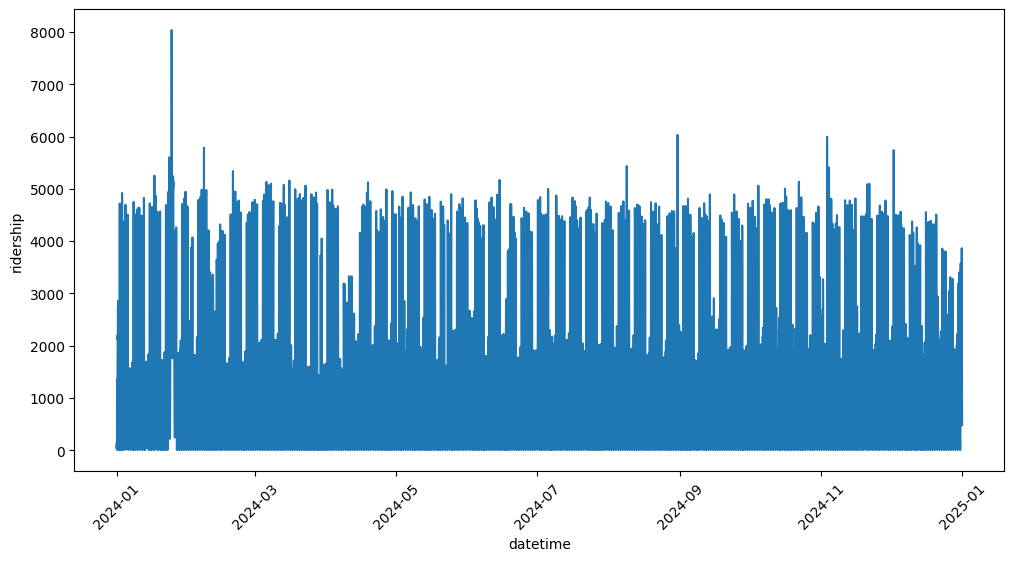

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=df1,
    y='ridership',
    x='datetime'
)

ax.tick_params(axis='x', labelrotation=45)
plt.show()

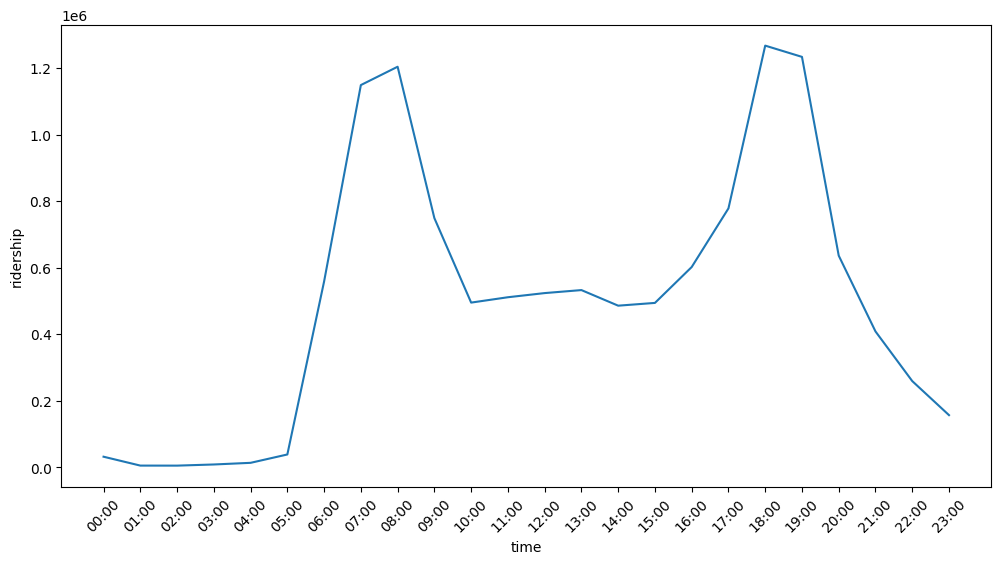

In [22]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(
    data=df2,
    y='ridership',
    x='time'
)

ax.tick_params(axis='x', labelrotation=45)
plt.show()

In [24]:
# anything 00:00:00 to 05:59:59 should be removed

cond = ktm_2024_df['datetime'].dt.hour.between(0,5)

ktm_2024_df[~cond].groupby('time')['ridership'].sum().reset_index()

,time,ridership
0,06:00,558981
1,07:00,1148953
2,08:00,1204024
3,09:00,749183
4,10:00,495390
5,11:00,511499
6,12:00,523968
7,13:00,532991
8,14:00,486154
9,15:00,494447
